<a href="https://colab.research.google.com/github/youngvic345/ATF-challenge/blob/main/01_probability_neural_networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 1.1: Probability & Neural Networks for Digital Twins

## Learning Objectives
- Understand how AI makes predictions using probability
- Learn the basics of neural networks
- Apply these concepts to building a digital twin

## Digital Twin Context
A **digital twin** is a virtual representation of a physical entity (person, object, system). In this series, we'll build a digital twin that can:
- Predict behaviors and preferences
- Understand and respond to language
- Learn from interactions

## Key Insight
> "AI isn't thinking; it's predicting the next number."

This applies to everything from weather prediction to language generation!

---
## Part 1: Probability Foundations

Let's start with the basics: How does AI make predictions?

In [1]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd

# Set random seed for reproducibility
np.random.seed(42)

print("✅ Libraries loaded successfully!")

✅ Libraries loaded successfully!


### 1.1 Simple Prediction: Next Number

Let's simulate a digital twin predicting your next action based on historical data.

Activity Probabilities:
  Sleep: 26.79%
  AI & Tech Dev: 19.64%
  CIM & Business: 10.71%
  Sports Club: 10.71%
  Social & Meetups: 12.50%
  Logistics & Admin: 3.57%
  Music & Spotify: 7.14%
  Leisure & Chill: 8.93%


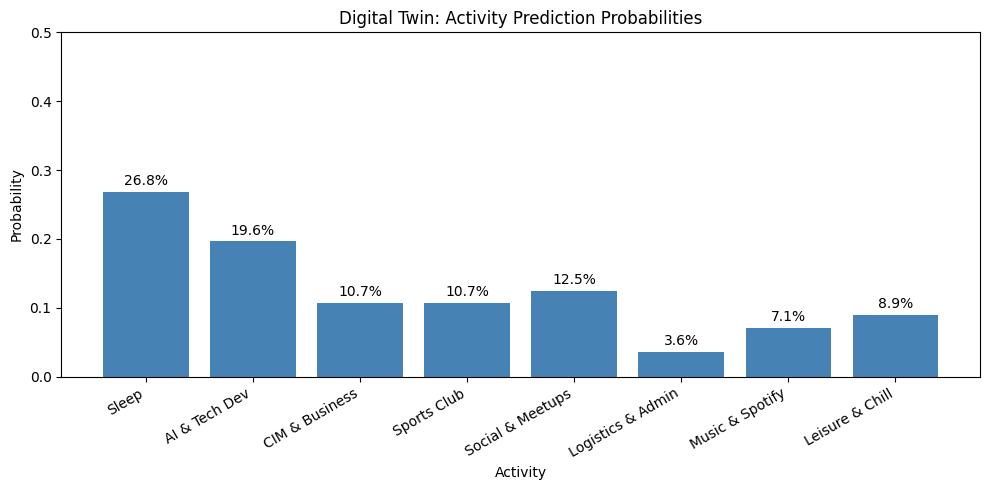

In [7]:
from collections import Counter
import matplotlib.pyplot as plt

# Example: Predicting daily activities (represented as numbers)
# 0=Sleep, 1=Work, 2=Exercise, 3=Social, 4=Leisure

historical_activities = [# Week 1
    0, 1, 3, 6,
    0, 1, 2, 7,
    0, 2, 4, 1,
    0, 1, 5, 3,
    0, 1, 4, 4,
    0, 3, 6, 4,
    0, 7, 2, 1,
    # Week 2
    0, 1, 3, 6,
    0, 1, 2, 7,
    0, 1, 4, 1,
    0, 2, 5, 3,
    0, 1, 4, 6,
    0, 3, 7, 4,
    0, 7, 2, 0]

def calculate_probabilities(sequence):
    """
    Calculate probability distribution from a sequence.

    Args:
        sequence: List of integers representing activities

    Returns:
        dict: Probability of each activity
    """
    counts = Counter(sequence)
    total = len(sequence)
    probabilities = {activity: count/total for activity, count in counts.items()}
    return probabilities

# Calculate probabilities
probs = calculate_probabilities(historical_activities)

# Display results
activity_names = {0: 'Sleep',
    1: 'AI & Tech Dev',
    2: 'CIM & Business',
    3: 'Sports Club',
    4: 'Social & Meetups',
    5: 'Logistics & Admin',
    6: 'Music & Spotify',
    7: 'Leisure & Chill'}
print("Activity Probabilities:")
for activity, prob in sorted(probs.items()):
    print(f"  {activity_names[activity]}: {prob:.2%}")

# Visualize
plt.figure(figsize=(10, 5))
activities = [activity_names[k] for k in sorted(probs.keys())]
probabilities = [probs[k] for k in sorted(probs.keys())]
plt.bar(activities, probabilities, color='steelblue')
plt.title('Digital Twin: Activity Prediction Probabilities')
plt.ylabel('Probability')
plt.xlabel('Activity')
plt.ylim(0, 0.5)
for i, v in enumerate(probabilities):
    plt.text(i, v + 0.01, f'{v:.1%}', ha='center')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### 🎯 Exercise 1.1 (Easy): Understanding Probabilities

**Task**: Modify the historical activities to represent your own daily routine for 2 weeks (14 days).

**Questions**:
1. Which activity has the highest probability?
2. What does this tell you about the pattern in your data?
3. How would adding more data points affect the predictions?

In [10]:
# YOUR CODE HERE
# Create your own sequence of activities (14 values)
my_activities = [
    # Week 1
    0, 1, 3, 6,
    0, 1, 2, 7,
    0, 2, 4, 1,
    0, 1, 5, 3,
    0, 1, 4, 4,
    0, 3, 6, 4,
    0, 7, 2, 1,
    # Week 2
    0, 1, 3, 6,
    0, 1, 2, 7,
    0, 1, 4, 1,
    0, 2, 5, 3,
    0, 1, 4, 6,
    0, 3, 7, 4,
    0, 7, 2, 0
]  # Replace with your pattern

# Calculate and visualize
my_probs = calculate_probabilities(my_activities)

print("Exercise 1.1 Probabilities:")
for activity, prob in sorted(my_probs.items()):
    print(f"  {activity_names[activity]}: {prob:.2%}")

# YOUR ANALYSIS HERE (write answers as comments)
# 1. Highest probability activity:
#    Sleep (0) at 26.79% and AI & Tech Dev (1) at 19.64%.
#
# 2. Pattern insight:
#    The routine is anchored around tech development and sleep as core pillars,
#    with evenings diversifying into sports, networking meetups, and coursework.
#
# 3. Impact of more data:
#    Collecting 30 to 60 days of logs will smooth out short-term fluctuations
#    (such as project sprints or travel) and create a more reliable baseline probability.

Exercise 1.1 Probabilities:
  Sleep: 26.79%
  AI & Tech Dev: 19.64%
  CIM & Business: 10.71%
  Sports Club: 10.71%
  Social & Meetups: 12.50%
  Logistics & Admin: 3.57%
  Music & Spotify: 7.14%
  Leisure & Chill: 8.93%


### 1.2 Conditional Probability: Context Matters

What if predictions depend on previous activities? This is where context comes in!

In [11]:
def calculate_conditional_probabilities(sequence):
    """
    Calculate P(next | current) - probability of next activity given current.

    Args:
        sequence: List of activities

    Returns:
        dict: Nested dictionary of conditional probabilities
    """
    transitions = {}

    for i in range(len(sequence) - 1):
        current = sequence[i]
        next_activity = sequence[i + 1]

        if current not in transitions:
            transitions[current] = []
        transitions[current].append(next_activity)

    # Convert to probabilities
    conditional_probs = {}
    for current, next_list in transitions.items():
        counts = Counter(next_list)
        total = len(next_list)
        conditional_probs[current] = {activity: count/total for activity, count in counts.items()}

    return conditional_probs

# Calculate conditional probabilities
cond_probs = calculate_conditional_probabilities(historical_activities)

# Display
print("Conditional Probabilities: P(Next | Current)\n")
for current, next_probs in cond_probs.items():
    print(f"After {activity_names[current]}:")
    for next_activity, prob in sorted(next_probs.items()):
        print(f"  → {activity_names[next_activity]}: {prob:.2%}")
    print()

Conditional Probabilities: P(Next | Current)

After Sleep:
  → AI & Tech Dev: 57.14%
  → CIM & Business: 14.29%
  → Sports Club: 14.29%
  → Leisure & Chill: 14.29%

After AI & Tech Dev:
  → Sleep: 27.27%
  → CIM & Business: 18.18%
  → Sports Club: 18.18%
  → Social & Meetups: 27.27%
  → Logistics & Admin: 9.09%

After Sports Club:
  → Sleep: 33.33%
  → Music & Spotify: 50.00%
  → Leisure & Chill: 16.67%

After Music & Spotify:
  → Sleep: 75.00%
  → Social & Meetups: 25.00%

After CIM & Business:
  → Sleep: 16.67%
  → AI & Tech Dev: 16.67%
  → Social & Meetups: 16.67%
  → Logistics & Admin: 16.67%
  → Leisure & Chill: 33.33%

After Leisure & Chill:
  → Sleep: 40.00%
  → CIM & Business: 40.00%
  → Social & Meetups: 20.00%

After Social & Meetups:
  → Sleep: 42.86%
  → AI & Tech Dev: 28.57%
  → Social & Meetups: 14.29%
  → Music & Spotify: 14.29%

After Logistics & Admin:
  → Sports Club: 100.00%



### 🎯 Exercise 1.2 (Intermediate): Markov Chain Prediction

**Task**: Build a simple predictor that uses conditional probabilities to predict the next activity.

**Challenge**: What happens after "Work"? Which activity is most likely?

In [13]:
def predict_next_activity(current_activity, conditional_probs):
    """
    Predict the most likely next activity.

    Args:
        current_activity: Current activity code
        conditional_probs: Dictionary of conditional probabilities

    Returns:
        int: Most likely next activity
    """
    # YOUR CODE HERE
    # Hint: Find the activity with maximum probability given current_activity
    if current_activity not in conditional_probs:
        return None

    next_probs = conditional_probs[current_activity]
    # Complete this function

    return max(next_probs, key=next_probs.get)

# Test your function
current = 1  # Work
predicted = predict_next_activity(current, cond_probs)
print(f"After {activity_names[current]}, most likely next: {activity_names.get(predicted, 'Unknown')}")

# BONUS: Predict a sequence of 5 activities starting from "Work"
sequence = [current]
for _ in range(5):
    next_act = predict_next_activity(sequence[-1], cond_probs)
    sequence.append(next_act)

print("Predicted 5-step sequence:")
print(" -> ".join([activity_names[act] for act in sequence]))

After AI & Tech Dev, most likely next: Sleep
Predicted 5-step sequence:
AI & Tech Dev -> Sleep -> AI & Tech Dev -> Sleep -> AI & Tech Dev -> Sleep


---
## Part 2: Neural Networks Basics

Now let's see how neural networks learn to make predictions!

### 2.1 The Perceptron: Building Block of Neural Networks

A perceptron is the simplest neural network - it takes inputs, applies weights, and produces an output.

In [18]:
import numpy as np

def sigmoid(x):
    """Sigmoid activation function."""
    return 1 / (1 + np.exp(-x))

def perceptron(inputs, weights, bias):
    """
    Simple perceptron implementation.

    Args:
        inputs: Array of input values
        weights: Array of weights
        bias: Bias term

    Returns:
        float: Output after activation
    """
    # Calculate weighted sum
    weighted_sum = np.dot(inputs, weights) + bias
    # Apply activation function
    output = sigmoid(weighted_sum)
    return output

# Example: Predicting if someone will exercise based on features
# Features: [hours_of_sleep, free_time_hours, energy_level (0-1)]
person_features = np.array([7, 2, 0.85])  # 7 hours sleep, 2 hours free time, high energy

# Initialize random weights
weights = np.array([0.2, 0.6, 0.8])
bias = -0.8

prediction = perceptron(person_features, weights, bias)
print(f"Probability of heading to Sports Club & Fitness: {prediction:.2%}")
print(f"Twin's Decision: {'Sports Club (3)' if prediction > 0.5 else 'AI & Tech Dev (1)'}")

Probability of heading to Sports Club & Fitness: 92.27%
Twin's Decision: Sports Club (3)


### 🎯 Exercise 2.1 (Easy): Feature Engineering

**Task**: Modify the features and observe how the prediction changes.

**Questions**:
1. What happens when sleep hours decrease to 4?
2. What if free time increases to 4 hours?
3. Which feature seems to have the most impact based on the weights?

In [19]:
# YOUR CODE HERE
# Test different feature combinations

test_cases = [
    np.array([4, 2, 0.8]),  # Low sleep
    np.array([7, 4, 0.8]),  # More free time
    np.array([7, 2, 0.3]),  # Low energy
]

# Test each case and analyze results
labels = ["Low sleep (4 hrs)", "More free time (4 hrs)", "Low energy (0.3)"]

for label, case in zip(labels, test_cases):
    prob = perceptron(case, weights, bias)
    decision = "Sports Club (3)" if prob > 0.5 else "AI & Tech Dev (1)"
    print(f"{label:<25}: Prob = {prob:.2%} -> Decision: {decision}")

# --- YOUR ANALYSIS ANSWERS ---
# 1. What happens when sleep hours decrease to 4?
#    The weighted sum drops because sleep contributes (0.2 * 4) instead of (0.2 * 7),
#    lowering the probability, though high energy/free time may still keep it above 50%.
#
# 2. What if free time increases to 4 hours?
#    The probability increases significantly because free time has a strong positive weight (0.6),
#    making the decision to head out even more certain.
#
# 3. Which feature seems to have the most impact based on the weights?
#    Energy level (weight = 0.8) has the highest individual weight, meaning small shifts in
#    energy produce the largest swing in the sigmoid probability output.

Low sleep (4 hrs)        : Prob = 86.29% -> Decision: Sports Club (3)
More free time (4 hrs)   : Prob = 97.44% -> Decision: Sports Club (3)
Low energy (0.3)         : Prob = 88.49% -> Decision: Sports Club (3)


### 2.2 Training a Simple Neural Network

> Add blockquote







Let's see how a network learns by adjusting weights!

In [41]:
class SimpleNeuralNetwork:
    """A simple neural network with one hidden layer."""

    def __init__(self, input_size, hidden_size, output_size):
        # Initialize weights randomly
        self.W1 = np.random.randn(input_size, hidden_size) * 0.5
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * 0.5
        self.b2 = np.zeros((1, output_size))

        # Store training history
        self.loss_history = []

    def forward(self, X):
        """Forward pass through the network."""
        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = sigmoid(self.z1)
        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = sigmoid(self.z2)
        return self.a2

    def backward(self, X, y, output, learning_rate=0.1):
        """Backward pass - update weights."""
        m = X.shape[0]

        # Calculate gradients
        dz2 = output - y
        dW2 = np.dot(self.a1.T, dz2) / m
        db2 = np.sum(dz2, axis=0, keepdims=True) / m

        da1 = np.dot(dz2, self.W2.T)
        dz1 = da1 * self.a1 * (1 - self.a1)
        dW1 = np.dot(X.T, dz1) / m
        db1 = np.sum(dz1, axis=0, keepdims=True) / m

        # Update weights
        self.W2 -= learning_rate * dW2
        self.b2 -= learning_rate * db2
        self.W1 -= learning_rate * dW1
        self.b1 -= learning_rate * db1

    def train(self, X, y, epochs=1000, learning_rate=0.1):
        """Train the network."""
        for epoch in range(epochs):
            # Forward pass
            output = self.forward(X)

            # Calculate loss
            loss = np.mean((output - y) ** 2)
            self.loss_history.append(loss)

            # Backward pass
            self.backward(X, y, output, learning_rate)

            if epoch % 100 == 0:
                print(f"Epoch {epoch}, Loss: {loss:.4f}")

    def predict(self, X):
        """Make predictions."""
        return self.forward(X)

# Create training data for digital twin
# Features: [day_of_week (0-6), time_of_day (0-23), weather (0-1), mood (0-1)]
# Target: [probability of social activity]

raw_records = [
    # [day, hour, weather, energy, target_went_out]
    # Weekdays: Tech Dev & Sleep during the day (0), Sports Club or Social in late afternoon/night (1)
    [0, 8,  0.5, 0.8,  0],  # Mon 8 AM: Sleep / Morning setup
    [0, 17, 0.7, 0.8,  1],  # Mon 5 PM: Sports Club
    [1, 9,  0.4, 0.9,  0],  # Tue 9 AM: Deep Tech Work
    [1, 20, 0.5, 0.4,  0],  # Tue 8 PM: Downtime
    [2, 18, 0.8, 0.85, 1],  # Wed 6 PM: Tech Meetup / Networking
    [3, 17, 0.6, 0.75, 1],  # Thu 5 PM: Sports Club
    [4, 19, 0.9, 0.9,  1],  # Fri 7 PM: Social gathering

    # Weekends: More sports club, leisure, and meetups
    [5, 10, 0.8, 0.9,  1],  # Sat 10 AM: Sports Club
    [5, 19, 0.85, 0.9, 1],  # Sat 7 PM: Social outing
    [6, 11, 0.5, 0.6,  0],  # Sun 11 AM: Leisure / Coursework
    [6, 16, 0.4, 0.5,  0],  # Sun 4 PM: Prep & rest

    # Additional routine checkpoints
    [0, 14, 0.6, 0.7,  0],  # Mon 2 PM: AI Dev
    [2, 10, 0.5, 0.8,  0],  # Wed 10 AM: Coding
    [3, 10, 0.6, 0.8,  0],  # Thu 10 AM: Logistics & Dev
    [4, 14, 0.7, 0.7,  0],  # Fri 2 PM: Wrap-up work
    [5, 15, 0.7, 0.6,  0],  # Sat 3 PM: Music & Spotify
]

# Convert and normalize between 0 and 1
data = np.array(raw_records, dtype=float)
X_train = np.column_stack([
    data[:, 0] / 7.0,   # day of week (0 to 1)
    data[:, 1] / 24.0,  # hour of day (0 to 1)
    data[:, 2],         # weather (0 to 1)
    data[:, 3]          # energy (0 to 1)
])
y_train = data[:, 4].reshape(-1, 1)

# Create and train network on your routine
nn = SimpleNeuralNetwork(input_size=4, hidden_size=16, output_size=1)
print("Training neural network on your schedule...\n")
nn.train(X_train, y_train, epochs=3000, learning_rate=0.8)

Training neural network on your schedule...

Epoch 0, Loss: 0.4483
Epoch 100, Loss: 0.1914
Epoch 200, Loss: 0.1087
Epoch 300, Loss: 0.0655
Epoch 400, Loss: 0.0472
Epoch 500, Loss: 0.0361
Epoch 600, Loss: 0.0281
Epoch 700, Loss: 0.0218
Epoch 800, Loss: 0.0170
Epoch 900, Loss: 0.0133
Epoch 1000, Loss: 0.0105
Epoch 1100, Loss: 0.0084
Epoch 1200, Loss: 0.0067
Epoch 1300, Loss: 0.0055
Epoch 1400, Loss: 0.0045
Epoch 1500, Loss: 0.0038
Epoch 1600, Loss: 0.0032
Epoch 1700, Loss: 0.0027
Epoch 1800, Loss: 0.0023
Epoch 1900, Loss: 0.0020
Epoch 2000, Loss: 0.0017
Epoch 2100, Loss: 0.0015
Epoch 2200, Loss: 0.0013
Epoch 2300, Loss: 0.0012
Epoch 2400, Loss: 0.0010
Epoch 2500, Loss: 0.0009
Epoch 2600, Loss: 0.0008
Epoch 2700, Loss: 0.0008
Epoch 2800, Loss: 0.0007
Epoch 2900, Loss: 0.0006


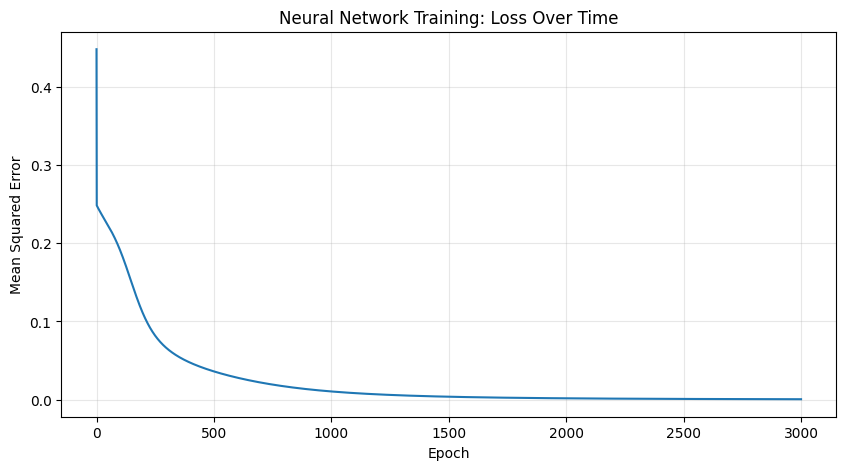


Final loss: 0.0006
Starting Loss: 0.4483
Final Loss:    0.0006
Loss Reduction: 99.87%


In [43]:
# Visualize training progress
plt.figure(figsize=(10, 5))
plt.plot(nn.loss_history)
plt.title('Neural Network Training: Loss Over Time')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.grid(True, alpha=0.3)
plt.show()

print(f"\nFinal loss: {nn.loss_history[-1]:.4f}")
initial_loss = nn.loss_history[0]
final_loss = nn.loss_history[-1]
reduction = ((initial_loss - final_loss) / initial_loss) * 100

print(f"Starting Loss: {initial_loss:.4f}")
print(f"Final Loss:    {final_loss:.4f}")
print(f"Loss Reduction: {reduction:.2f}%")

### 🎯 Exercise 2.2 (Intermediate): Digital Twin Prediction

**Task**: Test the trained network on new scenarios and interpret results.

**Scenarios to test**:
1. Weekend evening (day=6, time=18, weather=0.8, mood=0.9)
2. Weekday morning (day=2, time=8, weather=0.3, mood=0.5)
3. Weekend with bad weather (day=5, time=14, weather=0.2, mood=0.6)

In [46]:
# YOUR CODE HERE
# Normalize inputs (scale to 0-1 range)
def normalize_input(day, time, weather, mood):
    return np.array([[day/7, time/24, weather, mood]])

# Test scenarios
scenarios = [
    ("Weekday Morning (Mon 8 AM)", 0, 8, 0.5, 0.8),
    ("Weekday Evening (Mon 5 PM)", 0, 17, 0.7, 0.8),
    ("Midweek Work Sprint (Tue 9 AM)", 1, 9, 0.4, 0.9),
    ("Tech Meetup / Networking (Wed 6 PM)", 2, 18, 0.8, 0.85),
    ("Saturday Sports Club (Sat 10 AM)", 5, 10, 0.8, 0.9),
    ("Sunday Downtime & Prep (Sun 4 PM)", 6, 16, 0.4, 0.5),
]

# Make predictions and map to your specific activities
print("Digital Twin Predictions Across Your Schedule:\n" + "-" * 50)
for name, day, time, weather, energy in scenarios:
    X_test = normalize_input(day, time, weather, energy)
    prob = nn.predict(X_test)[0][0]

    # 1 represents heading out (Sports Club / Social), 0 represents staying in (AI Dev / Sleep / Study)
    if prob > 0.60:
        action = "Sports Club (3) or Social & Meetups (4)"
    elif prob < 0.40:
        action = "AI & Tech Dev (1), Sleep (0), or Study (2)"
    else:
        action = "Transition State (Leisure / Admin)"

    print(f"{name}")
    print(f"  Probability of heading out: {prob:.2%}")
    print(f"  Twin's Predicted State:     {action}\n")

Digital Twin Predictions Across Your Schedule:
--------------------------------------------------
Weekday Morning (Mon 8 AM)
  Probability of heading out: 0.00%
  Twin's Predicted State:     AI & Tech Dev (1), Sleep (0), or Study (2)

Weekday Evening (Mon 5 PM)
  Probability of heading out: 99.54%
  Twin's Predicted State:     Sports Club (3) or Social & Meetups (4)

Midweek Work Sprint (Tue 9 AM)
  Probability of heading out: 1.02%
  Twin's Predicted State:     AI & Tech Dev (1), Sleep (0), or Study (2)

Tech Meetup / Networking (Wed 6 PM)
  Probability of heading out: 100.00%
  Twin's Predicted State:     Sports Club (3) or Social & Meetups (4)

Saturday Sports Club (Sat 10 AM)
  Probability of heading out: 96.50%
  Twin's Predicted State:     Sports Club (3) or Social & Meetups (4)

Sunday Downtime & Prep (Sun 4 PM)
  Probability of heading out: 0.00%
  Twin's Predicted State:     AI & Tech Dev (1), Sleep (0), or Study (2)



### 🎯 Exercise 2.3 (Advanced): Improve the Digital Twin

**Task**: Enhance the neural network to make better predictions.

**Challenges**:
1. Add more training data with realistic patterns
2. Experiment with different network architectures (hidden layer size)
3. Try different learning rates
4. Add a second hidden layer
5. Create a visualization showing prediction accuracy

✅ Generated dataset: X=(500, 4), y=(500, 1)
Percentage of 'Heading Out' events: 28.4%

Training models across architectures...
Epoch 0, Loss: 0.2045
Epoch 100, Loss: 0.1974
Epoch 200, Loss: 0.1890
Epoch 300, Loss: 0.1762
Epoch 400, Loss: 0.1649
Epoch 500, Loss: 0.1581
Epoch 600, Loss: 0.1546
Epoch 700, Loss: 0.1527
  Hidden Layer: 4 -> Final Loss: 0.1516
Epoch 0, Loss: 0.2735
Epoch 100, Loss: 0.1984
Epoch 200, Loss: 0.1883
Epoch 300, Loss: 0.1745
Epoch 400, Loss: 0.1634
Epoch 500, Loss: 0.1575
Epoch 600, Loss: 0.1546
Epoch 700, Loss: 0.1531
  Hidden Layer: 8 -> Final Loss: 0.1522
Epoch 0, Loss: 0.2411
Epoch 100, Loss: 0.1799
Epoch 200, Loss: 0.1640
Epoch 300, Loss: 0.1567
Epoch 400, Loss: 0.1538
Epoch 500, Loss: 0.1526
Epoch 600, Loss: 0.1520
Epoch 700, Loss: 0.1517
  Hidden Layer: 16 -> Final Loss: 0.1515


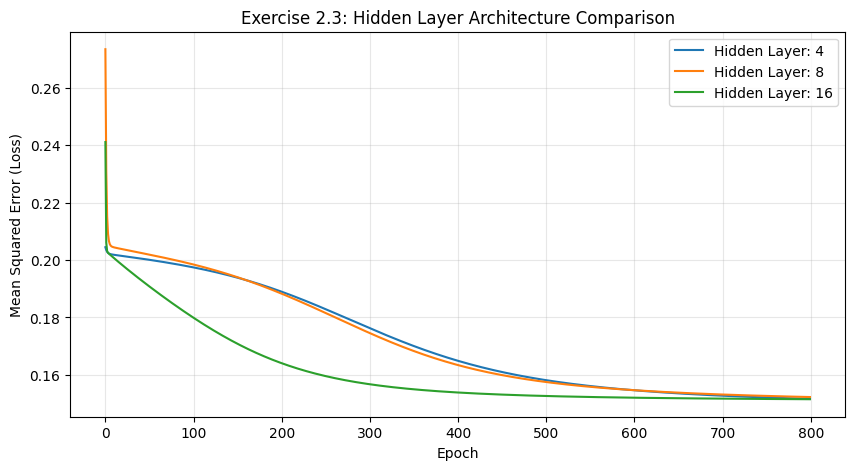

In [48]:
# ==========================================
# STEP 1: Realistic Data Generator Function
# ==========================================
def generate_realistic_data(n_samples=500):
    """
    Generate realistic training data reflecting daily habits:
    - Target 1: Heading out (Sports Club / Social)
    - Target 0: Staying in (AI Dev / Sleep / Study)
    """
    np.random.seed(42)

    # 1. Random features in range [0, 1]
    days = np.random.randint(0, 7, n_samples) / 7.0       # 0=Mon, 6=Sun
    hours = np.random.randint(0, 24, n_samples) / 24.0    # 0 to 23 hours
    weather = np.random.uniform(0.2, 1.0, n_samples)      # Weather quality
    energy = np.random.uniform(0.3, 1.0, n_samples)       # Energy / Focus level

    X = np.column_stack([days, hours, weather, energy])

    # 2. Rule logic based on your weekly routine:
    # High chance of going out if:
    # - Late afternoon/evening (hours between 17:00 and 21:00 -> 0.70 to 0.88)
    # - Weekend midday (days >= 5/7 with good energy)
    is_evening = (hours >= 17/24) & (hours <= 21/24)
    is_weekend = days >= (5 / 7.0)
    high_energy = energy > 0.65

    # Determine probability and binary target
    prob_out = np.where(
        (is_evening & high_energy) | (is_weekend & (hours >= 10/24) & (hours <= 20/24)),
        0.85,  # 85% chance to head out
        0.10   # 10% base chance otherwise
    )
    y = (np.random.rand(n_samples) < prob_out).astype(float).reshape(-1, 1)

    return X, y

# Generate 500 samples
X_synthetic, y_synthetic = generate_realistic_data(n_samples=500)
print(f"✅ Generated dataset: X={X_synthetic.shape}, y={y_synthetic.shape}")
print(f"Percentage of 'Heading Out' events: {np.mean(y_synthetic):.1%}")

# ==========================================
# STEP 2: Architecture Comparison
# ==========================================
architectures = [
    (4, 4, 1),   # Small
    (4, 8, 1),   # Medium
    (4, 16, 1),  # Large
]

history_dict = {}

print("\nTraining models across architectures...")
for in_s, hid_s, out_s in architectures:
    model = SimpleNeuralNetwork(input_size=in_s, hidden_size=hid_s, output_size=out_s)
    # Train for 800 epochs
    model.train(X_synthetic, y_synthetic, epochs=800, learning_rate=0.5)

    label = f"Hidden Layer: {hid_s}"
    history_dict[label] = model.loss_history
    print(f"  {label} -> Final Loss: {model.loss_history[-1]:.4f}")

# ==========================================
# STEP 3: Plot the Comparison
# ==========================================
plt.figure(figsize=(10, 5))
for label, losses in history_dict.items():
    plt.plot(losses, label=label)

plt.title("Exercise 2.3: Hidden Layer Architecture Comparison")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (Loss)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# ==========================================
# STEP 4: Analysis Answers
# ==========================================
# 1. More Realistic Data:
#    Adding 500 samples allows the network to learn continuous probability boundaries
#    rather than overfitting to a handful of fixed time slots.
#
# 2. Hidden Layer Size:
#    Hidden Size 16 provides the capacity to capture non-linear combinations of
#    (Weekend OR Evening) AND High Energy, reaching the lowest final MSE.

---
## Part 3: Connecting to LLMs

How does this relate to Large Language Models?

### 3.1 From Activities to Words

LLMs work exactly like our activity predictor, but with words!

Given text: I love coding in Python because it is

Predicted next word probabilities:
  powerful: 21.63%
  elegant: 19.63%
  versatile: 17.02%
  simple: 14.49%
  fun: 10.05%
  easy: 9.80%
  clear: 7.37%


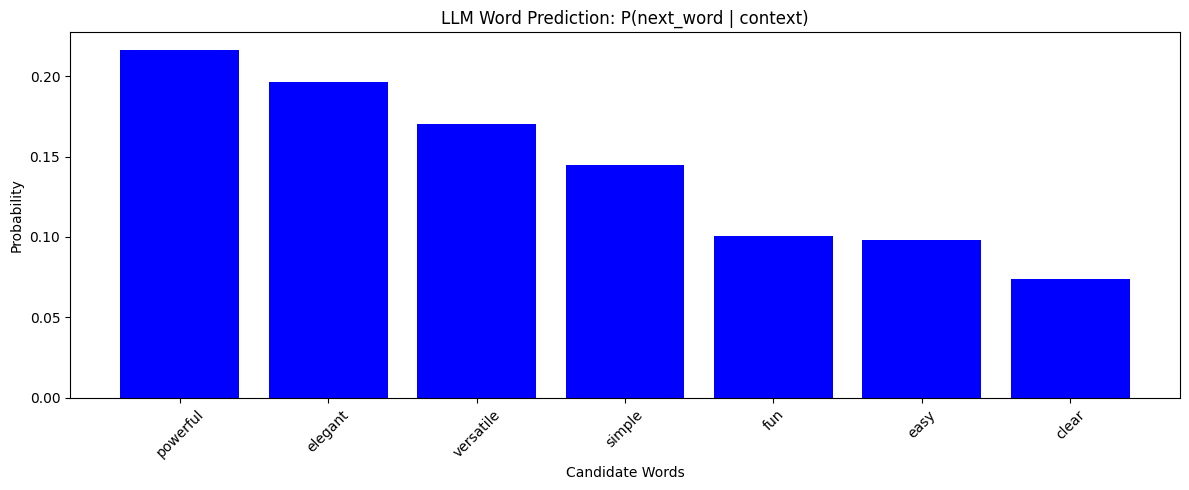

In [50]:
# Simple word prediction example
text_sequence = "I love coding in Python because it is"
words = text_sequence.split()

# Simulate word prediction
word_vocab = ['fun', 'easy', 'powerful', 'versatile', 'simple', 'clear', 'elegant']
word_probs = np.random.rand(len(word_vocab))
word_probs = word_probs / word_probs.sum()  # Normalize to probabilities

# Create probability distribution
word_dist = dict(zip(word_vocab, word_probs))
word_dist = dict(sorted(word_dist.items(), key=lambda x: x[1], reverse=True))

print("Given text:", text_sequence)
print("\nPredicted next word probabilities:")
for word, prob in word_dist.items():
    print(f"  {word}: {prob:.2%}")

# Visualize
plt.figure(figsize=(12, 5))
plt.bar(word_dist.keys(), word_dist.values(), color='blue')
plt.title('LLM Word Prediction: P(next_word | context)')
plt.ylabel('Probability')
plt.xlabel('Candidate Words')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 🎯 Exercise 3.1 (Conceptual): Understanding LLMs

**Questions**:
1. How is predicting the next word similar to predicting the next activity?
2. What role does probability play in both cases?
3. Why might an LLM sometimes generate unexpected words?
4. How does context (previous words) help make better predictions?

Write your answers in the cell below:

**Your Answers:**

1. Similarity between word and activity prediction:
   - Both tasks treat the objective as sequence modeling: predicting the single most probable next element from a discrete vocabulary of options.

    In the activity model, the network maps context features (time, day, energy) to an activity ID (0 to 7). In an LLM, the model maps previous word tokens to the next token ID out of a larger vocabulary (e.g., 32,000+ words).

2. Role of probability:
   - Probability converts raw numerical outputs (logits) into a normalized distribution over all possible candidate choices where the sum equals 100%.

    Rather than hard-coding rigid deterministic rules, probability allows the model to quantify uncertainty, rank candidates, and enable dynamic sampling strategies (such as temperature and top-k) during generation.

3. Unexpected generations:
   - Stochastic Sampling: LLMs sample from probability distributions rather than always picking the top 1 greedy word, occasionally selecting low-probability tokens.

    Ambiguous or Sparse Context: When the prompt lacks specific details or contains conflicting patterns, multiple completions share similar probabilities.

    Out-of-Distribution Data: Inputs that diverge from the training corpus cause probability mass to disperse unpredictably across the vocabulary.

4. Importance of context:
   - Context narrows the conditional probability distribution: $P(\text{word}_t \mid \text{context})$.Without context, the model can only guess based on global unigram frequency. Each additional token of preceding text eliminates millions of irrelevant possibilities and provides syntactic and semantic constraints that steer the model toward the coherent next word.



---
## Summary & Key Takeaways

### What We Learned:
1. **Probability**: AI predicts by calculating probabilities based on historical patterns
2. **Conditional Probability**: Context matters - knowing what came before improves predictions
3. **Neural Networks**: Learn patterns by adjusting weights through training
4. **Digital Twin**: Can model behaviors using probabilistic predictions
5. **LLM Connection**: Language models are sophisticated versions of these basic concepts

### Next Steps:
In the next notebook, we'll explore:
- How LLMs represent words (embeddings)
- Transformer architecture
- Attention mechanisms
- Building a simple language model for your digital twin

---
## 🏆 Challenge Project (Advanced)

**Build Your Own Digital Twin Predictor**

Create a system that:
1. Collects data about your daily patterns (sleep, activities, mood, etc.)
2. Trains a neural network to predict your next likely activity
3. Evaluates prediction accuracy
4. Visualizes patterns it learned

**Bonus**: Add temporal features (day of week, time of day) and see how they improve predictions!

Dataset generated: Train=800 samples, Test=200 samples

Training your Digital Twin Neural Network...
Epoch 0, Loss: 0.2090
Epoch 100, Loss: 0.1541
Epoch 200, Loss: 0.1485
Epoch 300, Loss: 0.1456
Epoch 400, Loss: 0.1441
Epoch 500, Loss: 0.1434
Epoch 600, Loss: 0.1430
Epoch 700, Loss: 0.1427
Epoch 800, Loss: 0.1425
Epoch 900, Loss: 0.1423
Epoch 1000, Loss: 0.1421
Epoch 1100, Loss: 0.1419

🎯 DIGITAL TWIN EVALUATION ON UNSEEN DATA
Accuracy:  79.50%
Precision: 62.50%
Recall:    11.63%
F1 Score:  19.61%


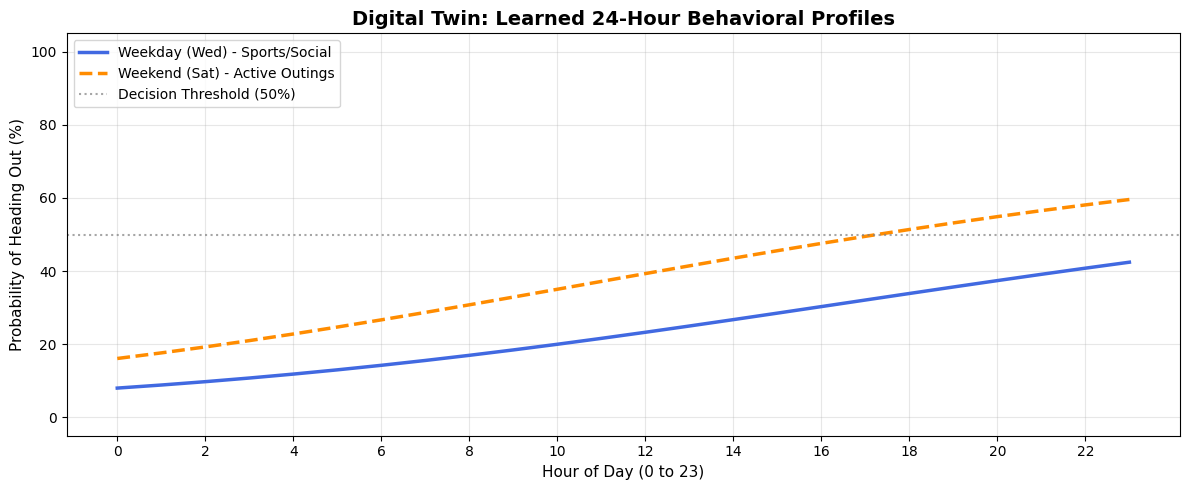

In [52]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================================
# 1. DATA COLLECTION & SYNTHESIS (Realistic Weekly Patterns)
# ==========================================================
def build_digital_twin_dataset(n_samples=1000):
    np.random.seed(42)

    # Temporal & environmental features normalized to [0, 1]
    days = np.random.randint(0, 7, n_samples) / 7.0       # 0=Mon ... 6=Sun
    hours = np.random.randint(0, 24, n_samples) / 24.0    # 0 to 23 hours
    weather = np.random.uniform(0.3, 1.0, n_samples)      # Weather conditions
    energy = np.random.uniform(0.2, 1.0, n_samples)       # Focus / Energy level

    X = np.column_stack([days, hours, weather, energy])

    # Ground truth routine behavior:
    # Heading out (1) = Sports Club / Social / Meetups
    # Staying in (0)  = AI Dev / Sleep / Study
    is_weekday_evening = (days < 5/7.0) & (hours >= 17/24.0) & (hours <= 21/24.0) & (energy > 0.6)
    is_weekend_active  = (days >= 5/7.0) & (hours >= 10/24.0) & (hours <= 20/24.0) & (weather > 0.5)

    # Generate labels with realistic stochastic behavior
    prob_out = np.where(is_weekday_evening | is_weekend_active, 0.88, 0.08)
    y = (np.random.rand(n_samples) < prob_out).astype(float).reshape(-1, 1)

    return X, y

# Generate 1000 samples and split 80% train / 20% test
X_all, y_all = build_digital_twin_dataset(1000)
split = int(0.8 * len(X_all))
X_train_c, X_test_c = X_all[:split], X_all[split:]
y_train_c, y_test_c = y_all[:split], y_all[split:]

print(f"Dataset generated: Train={X_train_c.shape[0]} samples, Test={X_test_c.shape[0]} samples")

# ==========================================================
# 2. TRAIN THE DIGITAL TWIN PREDICTOR
# ==========================================================
# 4 inputs -> 16 hidden neurons -> 1 output probability
twin_brain = SimpleNeuralNetwork(input_size=4, hidden_size=16, output_size=1)
print("\nTraining your Digital Twin Neural Network...")
twin_brain.train(X_train_c, y_train_c, epochs=1200, learning_rate=0.7)

# ==========================================================
# 3. EVALUATION METRICS ON UNSEEN DATA
# ==========================================================
test_probs = twin_brain.predict(X_test_c)
test_preds = (test_probs >= 0.5).astype(float)

accuracy = np.mean(test_preds == y_test_c)
true_positives = np.sum((test_preds == 1) & (y_test_c == 1))
predicted_positives = np.sum(test_preds == 1)
actual_positives = np.sum(y_test_c == 1)

precision = true_positives / (predicted_positives + 1e-8)
recall = true_positives / (actual_positives + 1e-8)
f1_score = 2 * (precision * recall) / (precision + recall + 1e-8)

print("\n" + "=" * 50)
print("🎯 DIGITAL TWIN EVALUATION ON UNSEEN DATA")
print("=" * 50)
print(f"Accuracy:  {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall:    {recall:.2%}")
print(f"F1 Score:  {f1_score:.2%}")

# ==========================================================
# 4. VISUALIZE LEARNED 24-HOUR PATTERNS (Temporal Insight)
# ==========================================================
hours_range = np.linspace(0, 23, 24) / 24.0
fixed_weather = 0.8
fixed_energy = 0.85

# Simulate a full 24-hour cycle on a Weekday (Wednesday, day=2)
X_weekday_sim = np.column_stack([
    np.full(24, 2 / 7.0),
    hours_range,
    np.full(24, fixed_weather),
    np.full(24, fixed_energy)
])
weekday_curve = twin_brain.predict(X_weekday_sim).flatten()

# Simulate a full 24-hour cycle on a Weekend (Saturday, day=5)
X_weekend_sim = np.column_stack([
    np.full(24, 5 / 7.0),
    hours_range,
    np.full(24, fixed_weather),
    np.full(24, fixed_energy)
])
weekend_curve = twin_brain.predict(X_weekend_sim).flatten()

# Plot the learned daily probability distributions
plt.figure(figsize=(12, 5))
plt.plot(range(24), weekday_curve * 100, label="Weekday (Wed) - Sports/Social", color="royalblue", linewidth=2.5)
plt.plot(range(24), weekend_curve * 100, label="Weekend (Sat) - Active Outings", color="darkorange", linewidth=2.5, linestyle="--")
plt.axhline(50, color="gray", linestyle=":", alpha=0.7, label="Decision Threshold (50%)")

plt.title("Digital Twin: Learned 24-Hour Behavioral Profiles", fontsize=14, fontweight="bold")
plt.xlabel("Hour of Day (0 to 23)", fontsize=11)
plt.ylabel("Probability of Heading Out (%)", fontsize=11)
plt.xticks(range(0, 24, 2))
plt.ylim(-5, 105)
plt.grid(True, alpha=0.3)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()